In [11]:
import sys
sys.path.append("C:/Users/anesa/Capuozzo/GBM-MGMT-Detection-master")  #ajouter le dossier a la liste de recherche de python


import os
import sys 
import json
import glob
import random
import collections
import time
import re

import numpy as np
import pandas as pd
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut
#import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import shutil

import torch
from torch import nn
from torch.utils import data as torch_data
from sklearn import model_selection as sk_model_selection
from torch.nn import functional as torch_functional
import torch.nn.functional as F

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

from tqdm import tqdm
import logging
from skimage.io import imread
#from torchviz import make_dot

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

from torch.autograd import Variable
from torch.optim import *
from scipy.io import loadmat, savemat
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, ConcatDataset, DataLoader, SubsetRandomSampler
#import torchio as tio
from torch.utils.tensorboard import SummaryWriter

import matplotlib.cm as cm
import matplotlib.animation as animation
#import plotly.graph_objects as go
#import plotly.io as pio
#pio.renderers.default = "notebook"
import math

from utils.dataset_utils import *
from utils.classifier_utils import *
from utils.neural_networks import *  #on utilise une implementation externe "efficientnet_pytorch_3D" pas le standard

logging.basicConfig(stream=sys.stdout, level=logging.INFO,
                    format='%(asctime)s - %(message)s', datefmt="%Y-%m-%d %H:%M:%S")

In [13]:
info = {}  #passer de mat a nii sans tt reecrire
info["ext"] = "mat"
#info["ext"] = "nii"
dir_path = "D:/PHD/rsna-miccai-brats-dataset/raw/train_"+info["ext"]   
test_dir_path = "D:/PHD/rsna-miccai-brats-dataset/raw/test_"+info["ext"]
tumor_only_dir_path = "../RSNA-BTC-Datasets/ec_train_"+info["ext"]
tumor_only_test_dir_path = "../RSNA-BTC-Datasets/ec_test_"+info["ext"]
no_tumor_dir_path = "../RSNA-BTC-Datasets/no_tumor_train_"+info["ext"]
#ext_test_1_dir_path = "../RSNA-BTC-Datasets/brats18_"+info["ext"]    #generalisation contre le overfitting, tester sur dautres bases
#ext_test_0_dir_path = "../RSNA-BTC-Datasets/OpenNeuroDS000221_ss_"+info["ext"]
#new_dir_path = "../RSNA-BTC-Datasets/UPENN-GBM_"+info["ext"]      #validation externe: verifier sur vrais patients,variations reels des images

In [15]:
# config du classifieur

chosen_net  = "alt" #3du, sim, alt, tun    #alt=alternativeClassifier (2D SliceBased)
if chosen_net == "alt":
    info["dims"] = 2 #3,2   #image 2D en entrée
    info["batch_size"] = 1#8,4,1   #1 slice a la fois
    sel_slices = 1 #None,1          #selection intelligente de slice
elif chosen_net == "tun":
    info["dims"] = 3 #3,2
    info["batch_size"] = 1#8,4,1
    sel_slices = None #None,1
else:
    info["dims"] = 3 #3,2
    info["batch_size"] = 4#8,4,1
    sel_slices = None #None,1
info["mri_types"] = ["KLF"] #["KLF"] ["FLAIR"] ["T1w"] ["FLAIR", "T2w"]
info["is_depth_wise"] = True       #convolutions depthwise separables: chaq canal traité seul
info["is_transformed"] = False
transform = None      #pas de rotation,flip,normalisation
info["output_size"] = 1  
info["is_multistep"] = True   #patient: agregation des predictions des slices
info["lr"] = 0.0001
info["is_adam"] = True
info["momentum"] = 0.9
info["is_10_fold"] = False  #geré manuelement
info["val_total_ratio"] = 0.2   #20% validation
info["is_internal_dataset"] = True
# Train and Val Origin:
# - m: Competition training or validation set
# - M: Competition training and validation set
# - f: Competition (tumor only) training or validation set
# - F: Competition (tumor only) training and validation set
# - t: External training or validation set
# - n: UPENN (tumor only) training or validation set
# - N: UPENN (tumor only) training and validation set
# - fn: Competition (tumor only) + UPENN (tumor only) training or validation
# - FN: Competition (tumor only) + UPENN (tumor only) training and validation
info["train_origin"] = "mn"
info["val_origin"] = "mn"
size = len(info["mri_types"])   #1 canal

"""
chosen_net  = "alt" #3du
info["dims"] = 2
info["mri_types"] = ["KLF"]
info["batch_size"] = 1#8
info["is_depth_wise"] = True
info["is_transformed"] = False
transform = None
info["output_size"] = 1
info["is_multistep"] = True
info["lr"] = 0.0005
info["is_adam"] = True
info["momentum"] = 0.9
info["is_10_fold"] = False
info["val_total_ratio"] = 0.2
info["is_internal_dataset"] = True
size = len(info["mri_types"])
sel_slices = 1
"""

"""
chosen_net  = "eff" #3du
info["dims"] = 3
info["mri_types"] = ["FLAIR"]
info["batch_size"] = 4#8
info["is_depth_wise"] = False
info["is_transformed"] = False
transform = None
info["output_size"] = 1
info["is_multistep"] = True
info["lr"] = 0.0005
info["is_adam"] = True
info["momentum"] = 0.9
info["is_10_fold"] = False
info["val_total_ratio"] = 0.1
info["is_internal_dataset"] = True
size = len(info["mri_types"])
sel_slices = None
"""
print(info)

{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': True, 'is_transformed': False, 'output_size': 1, 'is_multistep': True, 'lr': 0.0001, 'is_adam': True, 'momentum': 0.9, 'is_10_fold': False, 'val_total_ratio': 0.2, 'is_internal_dataset': True, 'train_origin': 'mn', 'val_origin': 'mn'}


In [17]:
#charger les donnees klf, appliquer les folds, construire les dataloades(entrés pour apprentissage)

import importlib
from utils import dataset_utils
importlib.reload(dataset_utils)

for i in range(5):     #changer les patients de val sur chaq iter
    print(f"-- FOLD N:{i}")
    to = "m"#info["train_origin"]
    print(f"Train origin: {to}") 
    packs = dataset_utils.generate_datasets(['KLF'], info, transform, sel_slices, m_path=dir_path)#, n_path=new_dir_path) #m_path=dir_path, 
    print(packs)  #charger les .mat
    loader_packs = dataset_utils.get_loaders(packs, info, is_fold=True, fold_num=i)    #application des folds, lire train_folds.csv, pour i: val et autres reste pour entrainment
    print(loader_packs) #getloadrs fusionne m_dataset_0 et m_dataset_0 : 614
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
    logging.info("Using CUDA...")

    pd.set_option("display.max_rows", None, "display.max_columns", None)
    print(loader_packs['KLF']['m_dataloaders'])
    selected_type = info["mri_types"][0]
    print(selected_type)
    dataloader = loader_packs[selected_type][f"{to}_dataloaders"]#m_dataloaders[0]   #entré pour entrennement

""" 
    # Train
    train_loader = dataloader[0]
    # Val
    val_loader = dataloader[1]

    m_model = try_and_get_model(chosen_net, info["dims"], size, info["is_depth_wise"], info["output_size"]) #

    print(info)
    m_modelfile = train_mri_type(m_model, device, info, epochs=100, pat=100, 
                           train_loader=train_loader, valid_loader=val_loader)
"""

-- FOLD N:0
Train origin: m
Type: KLF
2026-08-18 09:35:11 - (M0) Train/Val datasets size: 278
2026-08-18 09:35:11 - (M1) Train/Val datasets size: 307
{'KLF': {'m_dataset_0': <utils.dataset_utils.Dataset object at 0x00000262BD6C8A30>, 'm_dataset_1': <utils.dataset_utils.Dataset object at 0x00000262BA4C2F70>, 'f_dataset_0': None, 'f_dataset_1': None, 'h_dataset_0': None, 'n_dataset_0': None, 'n_dataset_1': None, 'mn_dataset_0': None, 'mn_dataset_1': None, 'fn_dataset_0': None, 'fn_dataset_1': None}}
Type: KLF
Length of concatenated dataset: 614
Length of concatenated dataset: 614
[([1, 2, 3, 4, 7, 8, 10, 11, 12, 14, 15, 16, 18, 20, 22, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 37, 38, 41, 42, 44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 56, 58, 59, 60, 61, 62, 63, 64, 65, 66, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 86, 87, 88, 89, 90, 92, 93, 94, 95, 96, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 110, 111, 112, 113, 114, 115, 116, 117, 119, 120, 121, 123, 124, 1

' \n    # Train\n    train_loader = dataloader[0]\n    # Val\n    val_loader = dataloader[1]\n\n    m_model = try_and_get_model(chosen_net, info["dims"], size, info["is_depth_wise"], info["output_size"]) #\n\n    print(info)\n    m_modelfile = train_mri_type(m_model, device, info, epochs=100, pat=100, \n                           train_loader=train_loader, valid_loader=val_loader)\n'

In [19]:
#recharger modeles entrainés (pipeline d'evaluation de croos_val)

import importlib
from utils import dataset_utils
importlib.reload(dataset_utils)

def infer_cases(cases=["A", "A_B", "B", "B_A", "AB"]):
    #cases = ["A", "A_B", "B", "B_A", "AB"] #["A", "A_B", "B", "B_A", "AB"]
    all_metrics = {}

    for case in cases:
        #case = "A" #A, A_B, B, B_A, AB
        if case == "A" or case == "A_B":
            
            folders_list = [
                "fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-m_Aug19_09-40-29",
                "fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-m_Aug19_10-15-21",
                "fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-m_Aug19_10-50-28",
                "fold3_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-m_Aug19_09-42-53",
                "fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-m_Aug19_10-18-34"
            ]
            
            folders_list = [
                "fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_14-05-43",
                "fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_14-59-16",
                "fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_15-53-18",
                "fold3_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_16-47-39",
                "fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_17-42-00"
            ]
        elif case == "B" or case == "B_A":
            folders_list = [
                "fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-n_Aug19_14-13-35",
                "fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-n_Aug19_14-45-29",
                "fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-n_Aug19_15-18-20",
                "fold3_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-n_Aug19_15-51-21",
                "fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-n_Aug19_16-23-56"
            ]
        elif case == "AB":
            folders_list = [
                "fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_14-21-30",
                "fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_16-20-40",
                "fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_18-21-17",
                "fold3_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_20-22-07",
                "fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_22-22-35"
            ]

        y_all = []         #concatener les pred des folds
        y_pred_all = []
        y_prob_all = []

        metrics = pd.DataFrame({"model": [], "AUC": [], "acc": [], "spec": [], "sens": [], "prec": []})
        i = 0

        for folder in folders_list:
            model_common_path = "C:/Users/anesa/Capuozzo/GBM-MGMT-Detection-master/2DFold/"# "D:/PHD/rsna-miccai-brats-dataset/raw/out_models/"   
            model_folder = model_common_path + folder

            model_basefile, info = get_best_model(model_folder)
            m_modelfile = model_folder + "/" + model_basefile
            transform = None
            size = len(info["mri_types"])
            sel_slices = 1 if info["dims"] == 2 else None
            chosen_net = "alt" if info["dims"] == 2 else "sim"

            m_model = try_and_get_model(chosen_net, info["dims"], size, info["is_depth_wise"], info["output_size"])

            #m_modelfile = m_modelfile_3d
            print(m_modelfile)
            print(info)
            print(f"-- FOLD N:{i}")

            if case == "A":
                to = "m"#info["train_origin"]
                data_idx = 1
            elif case == "A_B":
                to = "n"
                data_idx = 2 #full
            elif case == "B":
                to = "n"
                data_idx = 1
            elif case == "B_A":
                to = "m"
                data_idx = 2 #full
            elif case == "AB":
                to = "mn"
                data_idx = 1
            print(f"Train origin: {to}")
            if to == "m":
                packs = dataset_utils.generate_datasets(['KLF'], info, transform, sel_slices, m_path=dir_path) #m_path=dir_path, n_path=new_dir_path
            elif to == "n":
                packs = dataset_utils.generate_datasets(['KLF'], info, transform, sel_slices, n_path=new_dir_path)
            elif to == "mn":
                packs = dataset_utils.generate_datasets(['KLF'], info, transform, sel_slices, m_path=dir_path, n_path=new_dir_path)
            print(packs)
            loader_packs = dataset_utils.get_loaders(packs, info, is_fold=True, fold_num=i)   ###???? RECHARGE TT LES .MAT
            print(loader_packs)
            

            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            logging.info("Using CUDA...")

            pd.set_option("display.max_rows", None, "display.max_columns", None)
            #print(loader_packs['KLF']['m_dataloaders'])
            selected_type = info["mri_types"][0]
            print(selected_type)
            dataloader = loader_packs[selected_type][f"{to}_dataloaders"]#m_dataloaders[0]
            val_loader = dataloader[data_idx]
            #val_loader = dataloader[2] #full

            print("\nPREDICTIONS:")
            print(folder)
            #print(f"Test set: {to} (B)")
            test_loader = val_loader
            m_test_pred, ids, X, y, y_pred, y_prob = predict(m_model, device, m_modelfile, test_loader, size)
            pd_metrics = get_metrics(y, y_pred, y_prob, f"{folder}_{case}")
            y_all = y_all + y
            y_pred_all = y_pred_all + y_pred
            y_prob_all = y_prob_all + y_prob

            preddfA = pd.DataFrame({"BraTS21ID": ids, "MGMT_real_value": y, "MGMT_pred_value": y_pred, "MGMT_prob_value": y_prob}) 
            preddfA = preddfA.sort_values(by="BraTS21ID")
            preddfA.to_csv(f"pred_metrics/{folder}_{case}.csv", index=False)
            metrics = metrics.append(pd_metrics, ignore_index=True)
            #pd_metrics.to_csv(f"pred_metrics/{folder}_{to}_A_metrics.csv", index=False)

            print("----------\n")

            i += 1

        pd_metrics = get_metrics(y_all, y_pred_all, y_prob_all, f"all_{case}")
        metrics = metrics.append(pd_metrics, ignore_index=True)
        metrics.to_csv(f"pred_metrics/all_metrics_fold_2d_{case}.csv", index=False)
        all_metrics[case] = metrics
    return all_metrics

C:/Users/anesa/Capuozzo/GBM-MGMT-Detection-master/2DFold/fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_14-05-43/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e10-loss0.733-acc0.545-auc0.506.pth
{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': 'True', 'is_transformed': 'False', 'output_size': 1, 'is_multistep': 'True', 'lr': 0.0001, 'is_adam': 'True', 'momentum': 0.9, 'is_10_fold': 'False', 'val_total_ratio': 0.2, 'is_internal_dataset': 'True', 'train_origin': 'mn', 'val_origin': 'mn', 'net': 'RSNAAlternativeClassifierSingle2D'}
-- FOLD N:0
Train origin: m
Type: KLF
2026-08-18 09:47:30 - (M0) Train/Val datasets size: 278
2026-08-18 09:47:30 - (M1) Train/Val datasets size: 307
{'KLF': {'m_dataset_0': <utils.dataset_utils.Dataset object at 0x00000262BD763AF0>, 'm_dataset_1': <utils.dataset_utils.Dataset object at 0x00000262BD62A910>, 'f_dataset_0': None, 'f_dataset_1': None, 'h_dataset_0': None, 'n_dataset_0': None, 'n_dataset_1': None, 'mn_d

OSError: Cannot save file into a non-existent directory: 'pred_metrics'

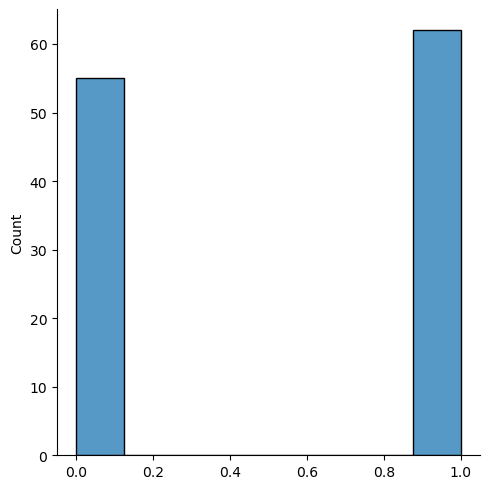

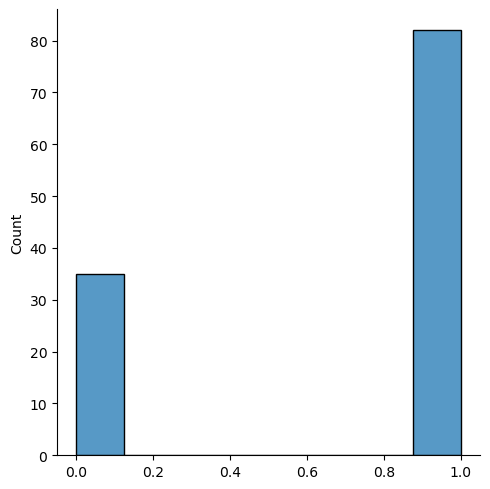

In [21]:
all_metrics = infer_cases()

In [23]:
all_metrics["A"]  

NameError: name 'all_metrics' is not defined

In [25]:
all_metrics["A_B"]

NameError: name 'all_metrics' is not defined

In [27]:
all_metrics["B"]

NameError: name 'all_metrics' is not defined

In [29]:
all_metrics["B_A"]

NameError: name 'all_metrics' is not defined

In [31]:
all_metrics["AB"]

NameError: name 'all_metrics' is not defined

../RSNA-BTC-Datasets/out_models/fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_14-05-43/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e10-loss0.733-acc0.545-auc0.506.pth
{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': 'True', 'is_transformed': 'False', 'output_size': 1, 'is_multistep': 'True', 'lr': 0.0001, 'is_adam': 'True', 'momentum': 0.9, 'is_10_fold': 'False', 'val_total_ratio': 0.2, 'is_internal_dataset': 'True', 'train_origin': 'mn', 'val_origin': 'mn', 'net': 'RSNAAlternativeClassifierSingle2D'}
-- FOLD N:0
Train origin: m
Type: KLF
2022-08-24 10:09:13 - (M0) Train/Val datasets size: 270
2022-08-24 10:09:13 - (M1) Train/Val datasets size: 303
{'KLF': {'m_dataset_0': <utils.dataset_utils.Dataset object at 0x7fabd43272e0>, 'm_dataset_1': <utils.dataset_utils.Dataset object at 0x7fac15096040>, 'f_dataset_0': None, 'f_dataset_1': None, 'h_dataset_0': None, 'n_dataset_0': None, 'n_dataset_1': None, 'mn_dataset_0': None, 'mn_dataset_1': 

../RSNA-BTC-Datasets/out_models/fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_14-59-16/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e50-loss0.995-acc0.587-auc0.523.pth
{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': 'True', 'is_transformed': 'False', 'output_size': 1, 'is_multistep': 'True', 'lr': 0.0001, 'is_adam': 'True', 'momentum': 0.9, 'is_10_fold': 'False', 'val_total_ratio': 0.2, 'is_internal_dataset': 'True', 'train_origin': 'mn', 'val_origin': 'mn', 'net': 'RSNAAlternativeClassifierSingle2D'}
-- FOLD N:1
Train origin: m
Type: KLF
2022-08-24 10:11:42 - (M0) Train/Val datasets size: 270
2022-08-24 10:11:42 - (M1) Train/Val datasets size: 303


/tmp/ipykernel_3603835/1072525201.py:120: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  metrics = metrics.append(pd_metrics, ignore_index=True)


{'KLF': {'m_dataset_0': <utils.dataset_utils.Dataset object at 0x7fabf770c4f0>, 'm_dataset_1': <utils.dataset_utils.Dataset object at 0x7fabf76a06d0>, 'f_dataset_0': None, 'f_dataset_1': None, 'h_dataset_0': None, 'n_dataset_0': None, 'n_dataset_1': None, 'mn_dataset_0': None, 'mn_dataset_1': None, 'fn_dataset_0': None, 'fn_dataset_1': None}}
Type: KLF
Length of concatenated dataset: 606
Length of concatenated dataset: 606
[([0, 2, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 28, 29, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 73, 74, 75, 76, 77, 79, 84, 85, 86, 88, 90, 91, 93, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 119, 120, 121, 123, 124, 125, 126, 127, 128, 129, 132, 133, 134, 135, 136, 137, 138, 140, 141, 142, 143, 144, 147, 148, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 16

../RSNA-BTC-Datasets/out_models/fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug22_15-53-18/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e10-loss0.694-acc0.595-auc0.530.pth
{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': 'True', 'is_transformed': 'False', 'output_size': 1, 'is_multistep': 'True', 'lr': 0.0001, 'is_adam': 'True', 'momentum': 0.9, 'is_10_fold': 'False', 'val_total_ratio': 0.2, 'is_internal_dataset': 'True', 'train_origin': 'mn', 'val_origin': 'mn', 'net': 'RSNAAlternativeClassifierSingle2D'}
-- FOLD N:2
Train origin: m
Type: KLF
2022-08-24 10:14:10 - (M0) Train/Val datasets size: 270
2022-08-24 10:14:10 - (M1) Train/Val datasets size: 303


/tmp/ipykernel_3603835/1072525201.py:120: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  metrics = metrics.append(pd_metrics, ignore_index=True)


... (74 outputs left out)

[([1, 3, 4, 5, 6, 7, 8, 9, 11, 12, 14, 15, 16, 18, 19, 20, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 56, 58, 59, 60, 61, 62, 63, 65, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 105, 107, 108, 110, 111, 112, 114, 115, 116, 117, 118, 119, 121, 122, 123, 124, 126, 129, 130, 131, 132, 134, 135, 136, 138, 139, 143, 144, 145, 146, 147, 149, 150, 151, 152, 153, 154, 156, 157, 158, 159, 160, 162, 164, 165, 166, 167, 169, 170, 173, 174, 175, 176, 177, 178, 179, 180, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 196, 197, 199, 201, 202, 203, 206, 207, 208, 209, 210, 211, 212, 214, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 246, 247, 249, 251, 252, 253, 254, 255, 256, 257, 258, 261, 263, 266, 267, 268, 269, 271, 272, 273, 274, 

Length of concatenated dataset: 1212
Length of concatenated dataset: 1212
[([1, 3, 4, 5, 6, 7, 8, 9, 11, 12, 14, 15, 16, 18, 19, 20, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 56, 58, 59, 60, 61, 62, 63, 65, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 105, 107, 108, 110, 111, 112, 114, 115, 116, 117, 118, 119, 121, 122, 123, 124, 126, 129, 130, 131, 132, 134, 135, 136, 138, 139, 143, 144, 145, 146, 147, 149, 150, 151, 152, 153, 154, 156, 157, 158, 159, 160, 162, 164, 165, 166, 167, 169, 170, 173, 174, 175, 176, 177, 178, 179, 180, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 196, 197, 199, 201, 202, 203, 206, 207, 208, 209, 210, 211, 212, 214, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 246, 247, 249, 251, 252, 253, 2

{'KLF': {'m_dataloaders': [<torch.utils.data.dataloader.DataLoader object at 0x7fabb0a93f70>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb0e3adf0>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb1171a90>], 'n_dataloaders': [<torch.utils.data.dataloader.DataLoader object at 0x7fabb0b5e550>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb0b5e160>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb0a22d90>], 'mn_dataloaders': [<torch.utils.data.dataloader.DataLoader object at 0x7fabb126ebe0>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb126eb50>, <torch.utils.data.dataloader.DataLoader object at 0x7fabb0e40a00>]}}
2022-08-24 11:53:11 - Using CUDA...
KLF

PREDICTIONS:
fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_22-22-35
2022-08-24 11:53:11 - Predict: ../RSNA-BTC-Datasets/out_models/fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_22-22-35/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e43-loss1.153-acc0.603-auc0.5

/tmp/ipykernel_3603835/1072525201.py:120: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  metrics = metrics.append(pd_metrics, ignore_index=True)
/tmp/ipykernel_3603835/1072525201.py:128: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  metrics = metrics.append(pd_metrics, ignore_index=True)


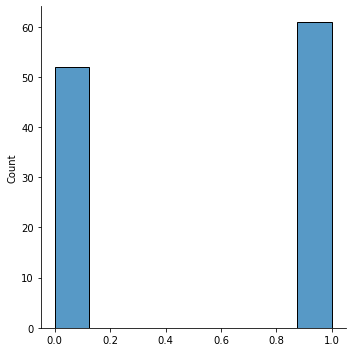

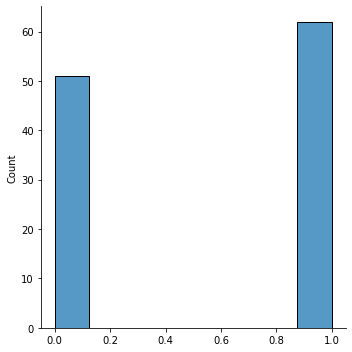

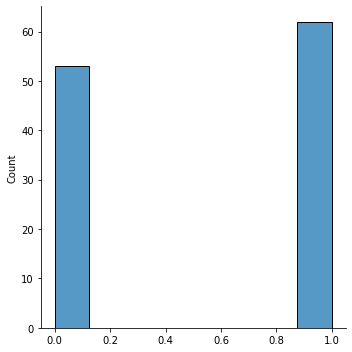

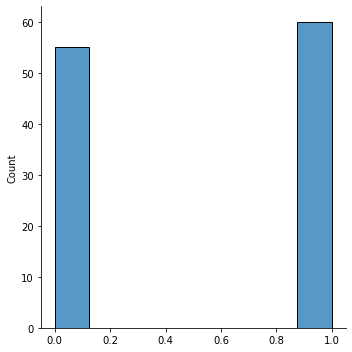

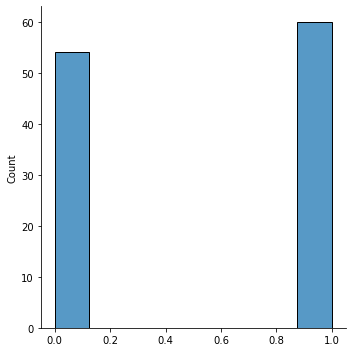

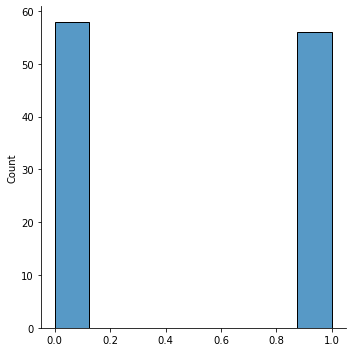

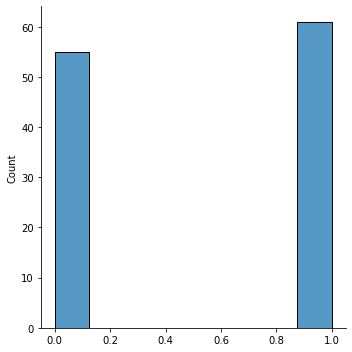

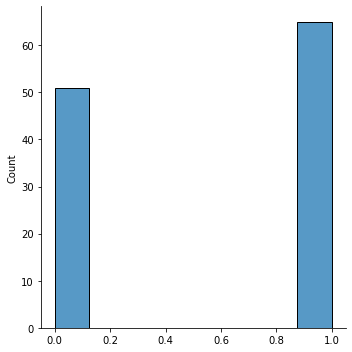

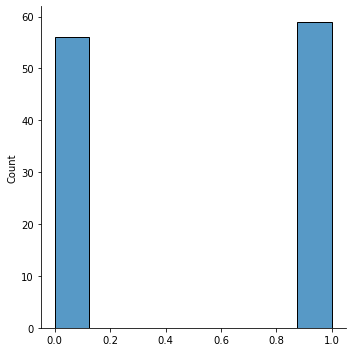

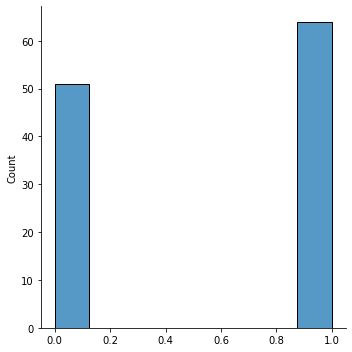

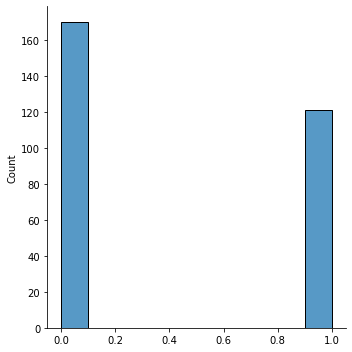

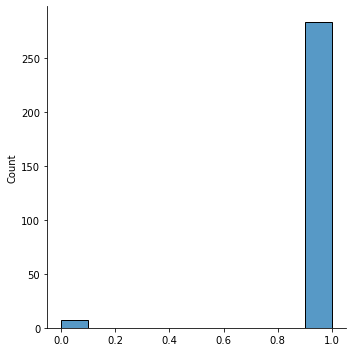

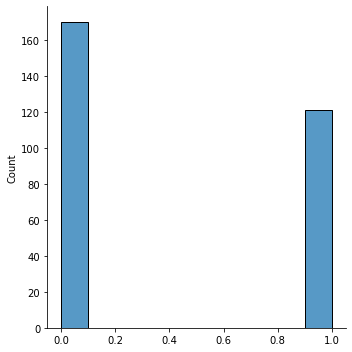

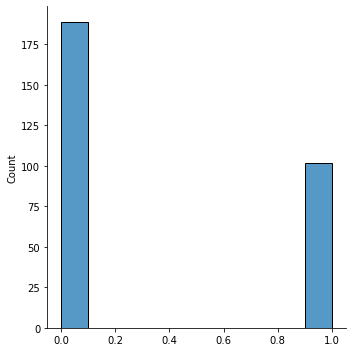

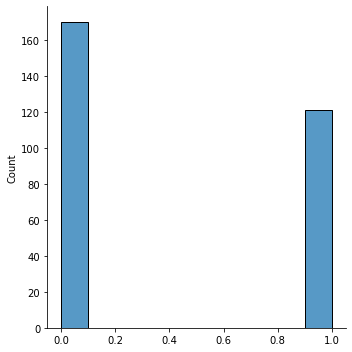

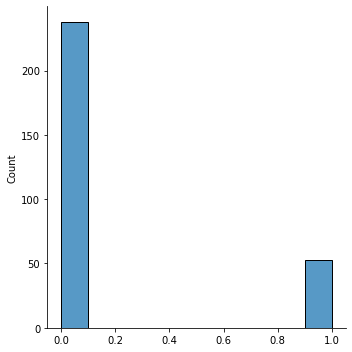

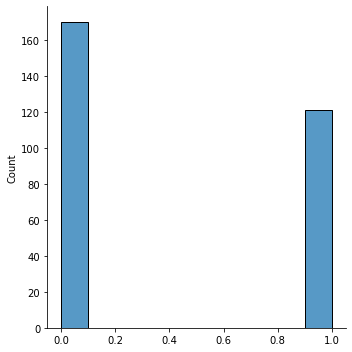

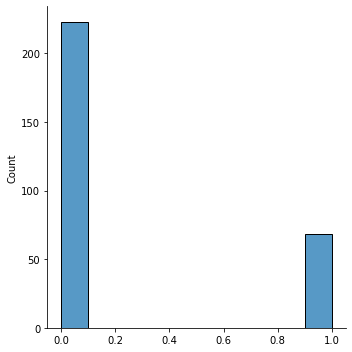

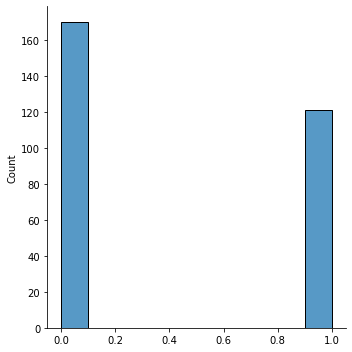

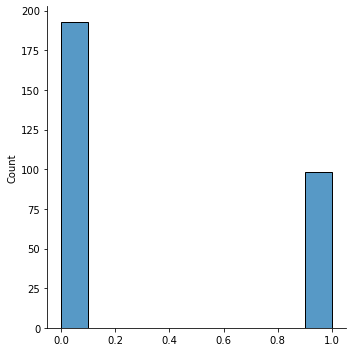

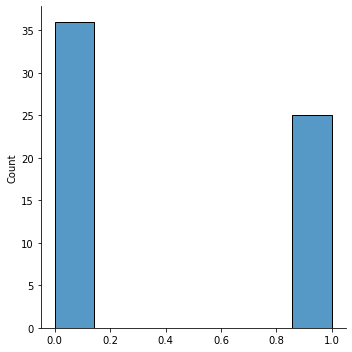

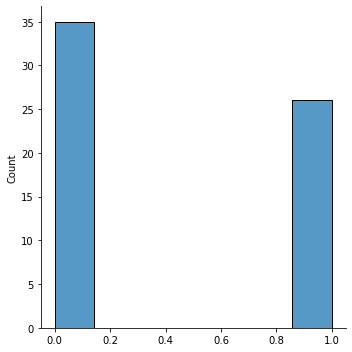

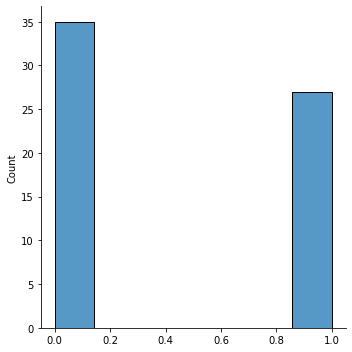

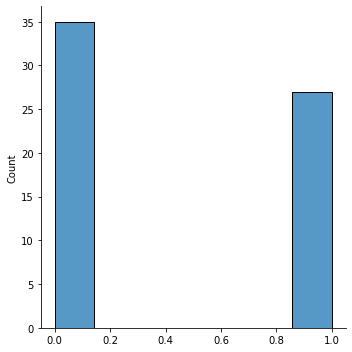

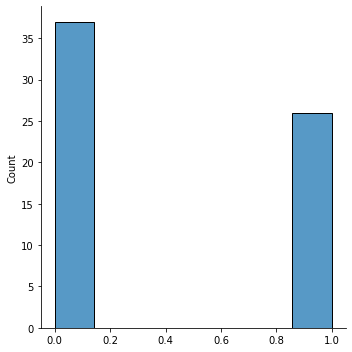

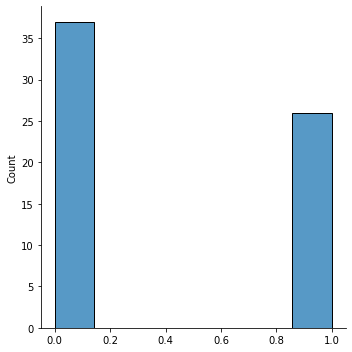

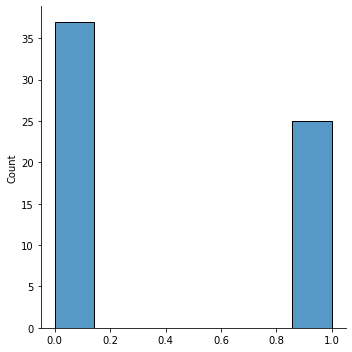

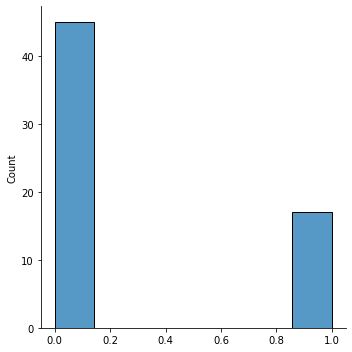

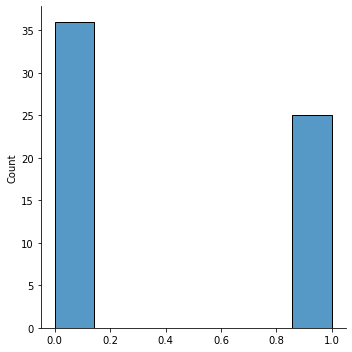

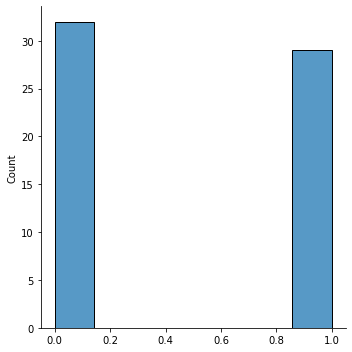

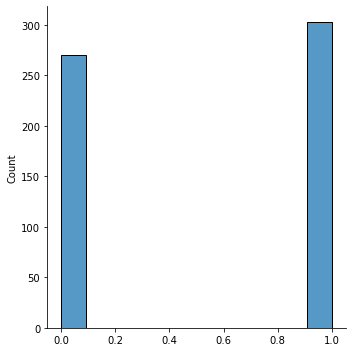

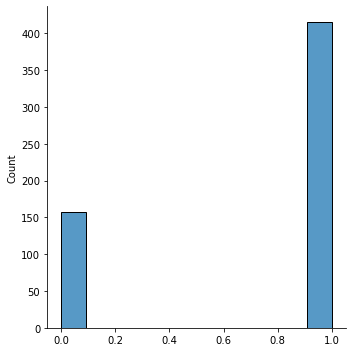

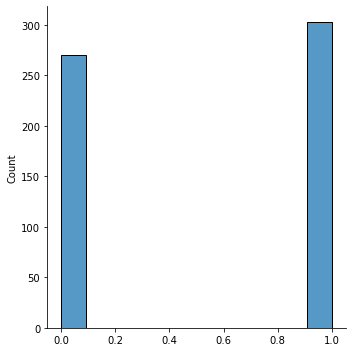

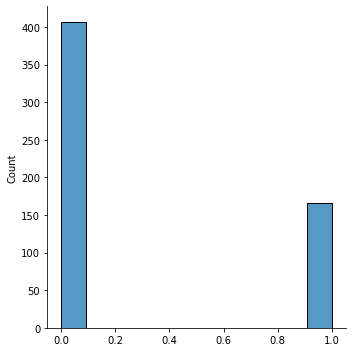

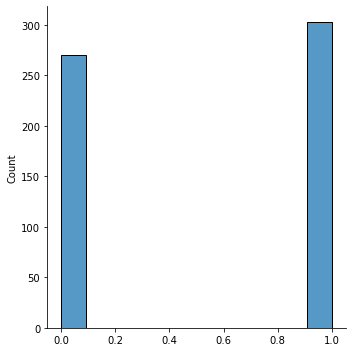

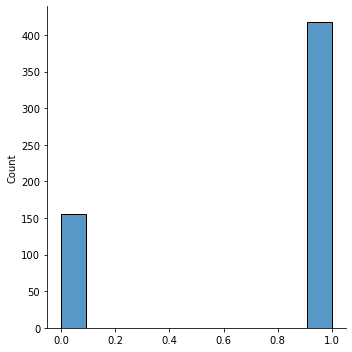

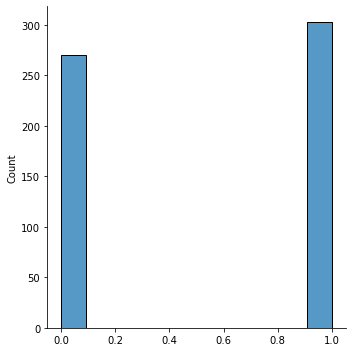

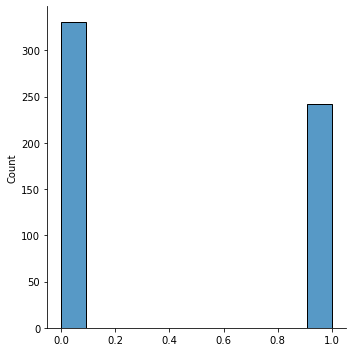

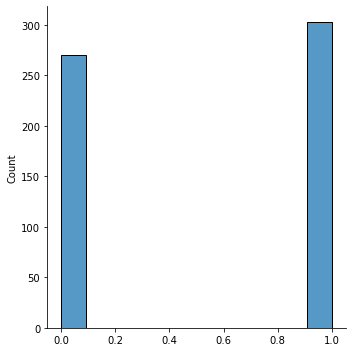

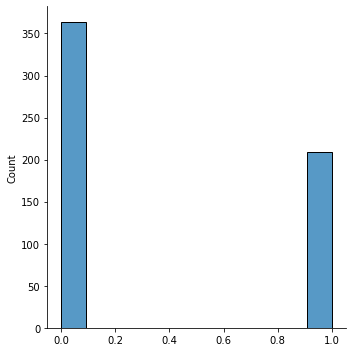

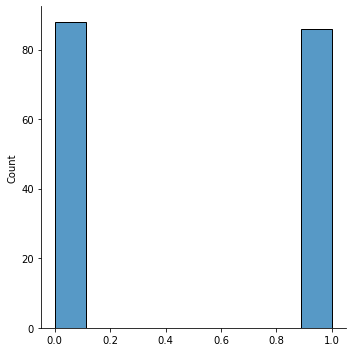

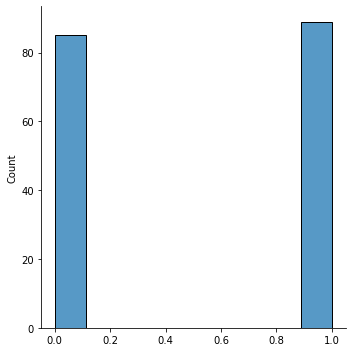

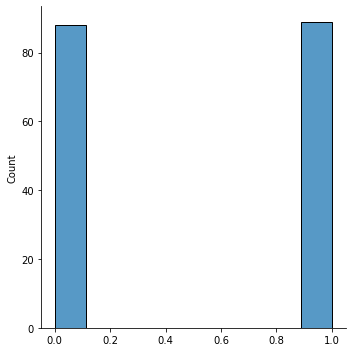

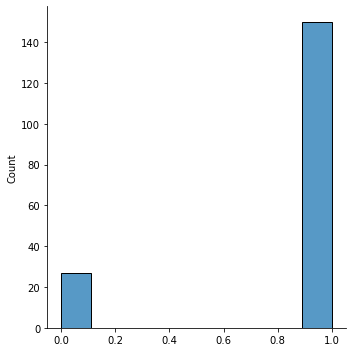

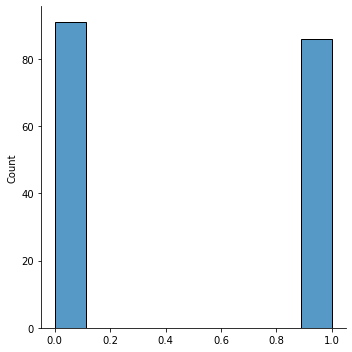

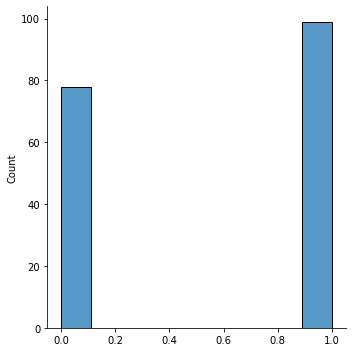

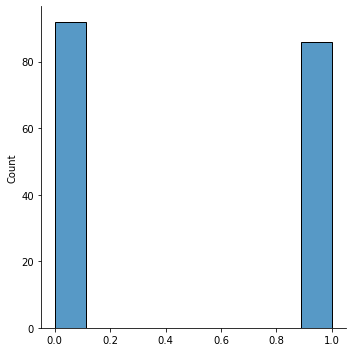

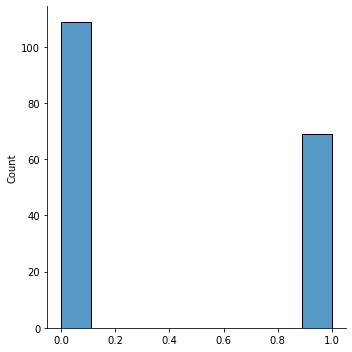

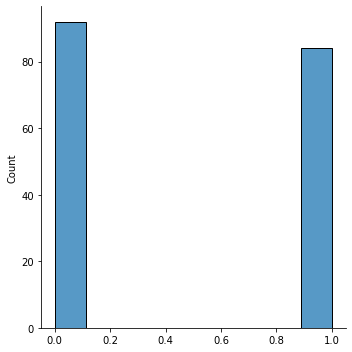

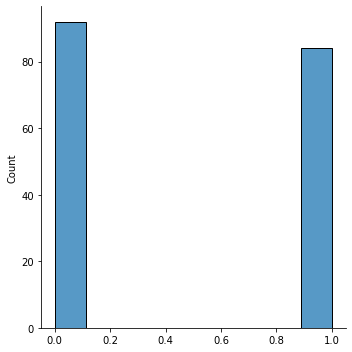

In [25]:
all_metrics_fixed = infer_cases()

In [26]:
all_metrics_fixed["A"]

,model,AUC,acc,spec,sens,prec
0,fold0_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.506305,0.548673,0.500000,0.590164,0.580645
1,fold1_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.522824,0.582609,0.566038,0.596774,0.616667
2,fold2_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.529630,0.578947,0.592593,0.566667,0.607143
3,fold3_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.648584,0.637931,0.581818,0.688525,0.646154
4,fold4_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.490315,0.539130,0.482143,0.593220,0.546875
5,all_A,0.535497,0.577661,0.544444,0.607261,0.599349


In [27]:
all_metrics_fixed["A_B"]

,model,AUC,acc,spec,sens,prec
0,fold0_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.500583,0.426117,0.029412,0.983471,0.419014
1,fold1_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.536558,0.549828,0.670588,0.380165,0.450980
2,fold2_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.531794,0.573883,0.835294,0.206612,0.471698
3,fold3_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.516091,0.549828,0.770588,0.239669,0.426471
4,fold4_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.518376,0.529210,0.664706,0.338843,0.418367
5,all_A_B,0.515144,0.525773,0.594118,0.429752,0.429752


In [28]:
all_metrics_fixed["B"]

,model,AUC,acc,spec,sens,prec
0,fold0_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.567778,0.524590,0.583333,0.440000,0.423077
1,fold1_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.634921,0.612903,0.657143,0.555556,0.555556
2,fold2_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.503119,0.523810,0.594595,0.423077,0.423077
3,fold3_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.538378,0.580645,0.756757,0.320000,0.470588
4,fold4_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.541111,0.540984,0.555556,0.520000,0.448276
5,all_B,0.555680,0.556634,0.629834,0.453125,0.464000


In [29]:
all_metrics_fixed["B_A"]

,model,AUC,acc,spec,sens,prec
0,fold0_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.542947,0.544503,0.307407,0.755776,0.550481
1,fold1_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.495862,0.481675,0.703704,0.283828,0.518072
2,fold2_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.528365,0.541012,0.300000,0.755776,0.547847
3,fold3_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.495337,0.499127,0.581481,0.425743,0.533058
4,fold4_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.486621,0.472949,0.614815,0.346535,0.502392
5,all_B_A,0.500655,0.507853,0.501481,0.513531,0.536182


In [30]:
all_metrics_fixed["AB"]

,model,AUC,acc,spec,sens,prec
0,fold0_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.524115,0.568966,0.556818,0.581395,0.561798
1,fold1_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.535240,0.519774,0.170455,0.865169,0.513333
2,fold2_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.540123,0.531073,0.472527,0.593023,0.515152
3,fold3_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.548407,0.522472,0.630435,0.406977,0.507246
4,fold4_RSNAAlternativeClassifierSingle2D-DW-SO-...,0.570523,0.545455,0.565217,0.523810,0.523810
5,all_AB,0.551713,0.537415,0.481153,0.596288,0.523422


../RSNA-BTC-Datasets/out_models/fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_16-20-40/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e5-loss0.708-acc0.521-auc0.535.pth
{'ext': 'mat', 'dims': 2, 'batch_size': 1, 'mri_types': ['KLF'], 'is_depth_wise': 'True', 'is_transformed': 'False', 'output_size': 1, 'is_multistep': 'True', 'lr': 0.0001, 'is_adam': 'True', 'momentum': 0.9, 'is_10_fold': 'False', 'val_total_ratio': 0.2, 'is_internal_dataset': 'True', 'train_origin': 'mn', 'val_origin': 'mn', 'net': 'RSNAAlternativeClassifierSingle2D'}
-- FOLD N:1
Train origin: m
Type: KLF
2022-08-22 09:50:33 - (M0) Train/Val datasets size: 270
2022-08-22 09:50:33 - (M1) Train/Val datasets size: 303
{'KLF': {'m_dataset_0': <utils.dataset_utils.Dataset object at 0x7fabf7dbdc40>, 'm_dataset_1': <utils.dataset_utils.Dataset object at 0x7fac150d5910>, 'f_dataset_0': None, 'f_dataset_1': None, 'h_dataset_0': None, 'n_dataset_0': None, 'n_dataset_1': None, 'mn_dataset_0': None, 'mn_dataset_1': N

Top idx of 00327_KLF.mat: 126
Top idx of 00336_KLF.mat: 125
Top idx of 00339_KLF.mat: 116
Top idx of 00341_KLF.mat: 91
Top idx of 00343_KLF.mat: 97
Top idx of 00346_KLF.mat: 90
Top idx of 00347_KLF.mat: 95
Top idx of 00348_KLF.mat: 98
Top idx of 00349_KLF.mat: 68
Top idx of 00351_KLF.mat: 66
Top idx of 00353_KLF.mat: 124
Top idx of 00356_KLF.mat: 93
Top idx of 00373_KLF.mat: 97
Top idx of 00376_KLF.mat: 97
Top idx of 00377_KLF.mat: 97
Top idx of 00378_KLF.mat: 93
Top idx of 00379_KLF.mat: 102
Top idx of 00380_KLF.mat: 88
Top idx of 00382_KLF.mat: 98
Top idx of 00387_KLF.mat: 95
Top idx of 00388_KLF.mat: 68
Top idx of 00389_KLF.mat: 101
Top idx of 00390_KLF.mat: 94
Top idx of 00391_KLF.mat: 98
Top idx of 00392_KLF.mat: 109
Top idx of 00395_KLF.mat: 119
Top idx of 00397_KLF.mat: 80
Top idx of 00399_KLF.mat: 98
Top idx of 00401_KLF.mat: 112
Top idx of 00402_KLF.mat: 66
Top idx of 00405_KLF.mat: 123
Top idx of 00407_KLF.mat: 71
Top idx of 00410_KLF.mat: 99
Top idx of 00412_KLF.mat: 97
Top 

Top idx of 00281_KLF.mat: 79
Top idx of 00282_KLF.mat: 57
Top idx of 00284_KLF.mat: 99
Top idx of 00285_KLF.mat: 96
Top idx of 00291_KLF.mat: 93
Top idx of 00293_KLF.mat: 102
Top idx of 00294_KLF.mat: 77
Top idx of 00296_KLF.mat: 98
Top idx of 00299_KLF.mat: 96
Top idx of 00303_KLF.mat: 129
Top idx of 00304_KLF.mat: 53
Top idx of 00305_KLF.mat: 92
Top idx of 00306_KLF.mat: 95
Top idx of 00311_KLF.mat: 96
Top idx of 00313_KLF.mat: 96
Top idx of 00317_KLF.mat: 100
Top idx of 00321_KLF.mat: 98
Top idx of 00322_KLF.mat: 65
Top idx of 00328_KLF.mat: 98
Top idx of 00329_KLF.mat: 94
Top idx of 00331_KLF.mat: 90
Top idx of 00332_KLF.mat: 102
Top idx of 00334_KLF.mat: 101
Top idx of 00338_KLF.mat: 131
Top idx of 00340_KLF.mat: 91
Top idx of 00344_KLF.mat: 100
Top idx of 00350_KLF.mat: 84
Top idx of 00352_KLF.mat: 57
Top idx of 00359_KLF.mat: 62
Top idx of 00360_KLF.mat: 101
Top idx of 00364_KLF.mat: 103
Top idx of 00366_KLF.mat: 99
Top idx of 00367_KLF.mat: 99
Top idx of 00369_KLF.mat: 119
Top 

Top idx of 00218_KLF.mat: 97
Top idx of 00219_KLF.mat: 100
Top idx of 00221_KLF.mat: 93
Top idx of 00227_KLF.mat: 98
Top idx of 00228_KLF.mat: 117
Top idx of 00231_KLF.mat: 135
Top idx of 00236_KLF.mat: 97
Top idx of 00237_KLF.mat: 92
Top idx of 00238_KLF.mat: 94
Top idx of 00239_KLF.mat: 140
Top idx of 00241_KLF.mat: 96
Top idx of 00242_KLF.mat: 130
Top idx of 00243_KLF.mat: 92
Top idx of 00247_KLF.mat: 126
Top idx of 00249_KLF.mat: 128
Top idx of 00251_KLF.mat: 90
Top idx of 00258_KLF.mat: 93
Top idx of 00259_KLF.mat: 107
Top idx of 00261_KLF.mat: 137
Top idx of 00262_KLF.mat: 104
Top idx of 00266_KLF.mat: 68
Top idx of 00267_KLF.mat: 121
Top idx of 00269_KLF.mat: 107
Top idx of 00274_KLF.mat: 97
Top idx of 00275_KLF.mat: 137
Top idx of 00280_KLF.mat: 100
Top idx of 00283_KLF.mat: 96
Top idx of 00286_KLF.mat: 102
Top idx of 00288_KLF.mat: 98
Top idx of 00289_KLF.mat: 122
Top idx of 00290_KLF.mat: 137
Top idx of 00297_KLF.mat: 69
Top idx of 00298_KLF.mat: 101
Top idx of 00300_KLF.mat:

Top idx of 00117_KLF.mat: 96
Top idx of 00128_KLF.mat: 64
Top idx of 00134_KLF.mat: 99
Top idx of 00136_KLF.mat: 132
Top idx of 00138_KLF.mat: 68
Top idx of 00139_KLF.mat: 116
Top idx of 00140_KLF.mat: 92
Top idx of 00144_KLF.mat: 98
Top idx of 00146_KLF.mat: 121
Top idx of 00155_KLF.mat: 98
Top idx of 00156_KLF.mat: 105
Top idx of 00159_KLF.mat: 97
Top idx of 00160_KLF.mat: 60
Top idx of 00166_KLF.mat: 89
Top idx of 00171_KLF.mat: 96
Top idx of 00177_KLF.mat: 51
Top idx of 00178_KLF.mat: 128
Top idx of 00185_KLF.mat: 103
Top idx of 00186_KLF.mat: 98
Top idx of 00187_KLF.mat: 119
Top idx of 00188_KLF.mat: 104
Top idx of 00196_KLF.mat: 98
Top idx of 00197_KLF.mat: 98
Top idx of 00199_KLF.mat: 102
Top idx of 00203_KLF.mat: 118
Top idx of 00204_KLF.mat: 99
Top idx of 00210_KLF.mat: 95
Top idx of 00212_KLF.mat: 99
Top idx of 00220_KLF.mat: 89
Top idx of 00222_KLF.mat: 95
Top idx of 00230_KLF.mat: 112
Top idx of 00233_KLF.mat: 74
Top idx of 00234_KLF.mat: 97
Top idx of 00235_KLF.mat: 70
Top

{'KLF': {'m_dataloaders': [<torch.utils.data.dataloader.DataLoader object at 0x7fabf7e26100>, <torch.utils.data.dataloader.DataLoader object at 0x7fabf769d370>, <torch.utils.data.dataloader.DataLoader object at 0x7fabf769d4c0>], 'n_dataloaders': None, 'mn_dataloaders': None}}
2022-08-22 09:51:57 - Using CUDA...
KLF

PREDICTIONS:
fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_16-20-40
2022-08-22 09:51:57 - Predict: ../RSNA-BTC-Datasets/out_models/fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_16-20-40/RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn-e5-loss0.708-acc0.521-auc0.535.pth 606
Top idx of 00683_KLF.mat: 134
Top idx of 00294_KLF.mat: 77
Top idx of 00724_KLF.mat: 82
Top idx of 00621_KLF.mat: 55
Top idx of 00000_KLF.mat: 101
Top idx of 00154_KLF.mat: 61
Top idx of 00576_KLF.mat: 136
Top idx of 00417_KLF.mat: 56
Top idx of 00281_KLF.mat: 79
Top idx of 00654_KLF.mat: 56
Top idx of 00136_KLF.mat: 132
Top idx of 00166_KLF.mat: 89
Top idx of 00286_KLF.mat: 102
To

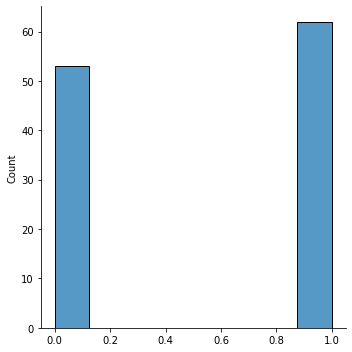

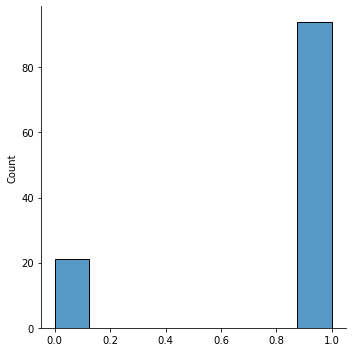

In [14]:
import importlib
from utils import dataset_utils
from utils import neural_networks
importlib.reload(dataset_utils)

folders_list = [
    #"fold0_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_14-21-30",
    "fold1_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_16-20-40",
    #"fold2_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_18-21-17",
    #"fold3_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_20-22-07",
    #"fold4_RSNAAlternativeClassifierSingle2D-DW-SO-KLF-mn_Aug20_22-22-35"
]

y_all = []
y_pred_all = []
y_prob_all = []

i = 1

for folder in folders_list:
    model_common_path = "../RSNA-BTC-Datasets/out_models/"
    model_folder = model_common_path + folder

    model_basefile, info = neural_networks.get_best_model(model_folder)
    m_modelfile = model_folder + "/" + model_basefile
    transform = None
    size = len(info["mri_types"])
    sel_slices = 1 if info["dims"] == 2 else None
    chosen_net = "alt" if info["dims"] == 2 else "sim"
    
    m_model = neural_networks.try_and_get_model(chosen_net, info["dims"], size, info["is_depth_wise"], info["output_size"])

    #m_modelfile = m_modelfile_3d
    print(m_modelfile)
    print(info)
    print(f"-- FOLD N:{i}")
    to = "m"#info["train_origin"]
    print(f"Train origin: {to}")
    packs = dataset_utils.generate_datasets(['KLF'], info, transform, sel_slices, m_path=dir_path)#, n_path=new_dir_path) #m_path=dir_path, n_path=new_dir_path
    print(packs)
    loader_packs = dataset_utils.get_loaders(packs, info, is_fold=True, fold_num=i)#, extra="kai")
    print(loader_packs)
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    logging.info("Using CUDA...")

    pd.set_option("display.max_rows", None, "display.max_columns", None)
    #print(loader_packs['KLF']['m_dataloaders'])
    selected_type = info["mri_types"][0]
    print(selected_type)
    dataloader = loader_packs[selected_type][f"{to}_dataloaders"]#m_dataloaders[0]
    val_loader = dataloader[1]
    #val_loader = dataloader[2] #full
    
    print("\nPREDICTIONS:")
    print(folder)
    #print(f"Test set: {to} (B)")
    
    test_loader = val_loader
    m_test_pred, ids, X, y, y_pred, y_prob = predict(m_model, device, m_modelfile, test_loader, size)
    pd_metrics = get_metrics(y, y_pred, y_prob, f"{folder}_A")
    y_all = y_all + y
    y_pred_all = y_pred_all + y_pred
    y_prob_all = y_prob_all + y_prob
    
    preddfA = pd.DataFrame({"BraTS21ID": ids, "MGMT_real_value": y, "MGMT_pred_value": y_pred, "MGMT_prob_value": y_prob}) 
    preddfA = preddfA.sort_values(by="BraTS21ID")
    print(preddfA)
    """
    preddfA.to_csv(f"pred_metrics/{folder}_AB.csv", index=False)
    metrics = metrics.append(pd_metrics, ignore_index=True)
    #pd_metrics.to_csv(f"pred_metrics/{folder}_{to}_A_metrics.csv", index=False)
    
    print("----------\n")
    """

#pd_metrics = get_metrics(y_all, y_pred_all, y_prob_all, f"all_AB")
#metrics = metrics.append(pd_metrics, ignore_index=True)
#metrics.to_csv(f"pred_metrics/all_metrics_fold_2d_AB.csv", index=False)

Prediction AUC: 0.5232
Prediction Accuracy: 0.5393
Prediction Specificity: 0.5111
Prediction Sensitivity: 0.5644
Prediction Precision: 0.5644
Prediction AUC: 0.5232
Prediction Accuracy: 0.5550
Prediction Specificity: 0.4963
Prediction Sensitivity: 0.6073
Prediction Precision: 0.5750
Prediction AUC: 0.5266
Prediction Accuracy: 0.5120
Prediction Specificity: 0.5200
Prediction Sensitivity: 0.5008
Prediction Precision: 0.4262
Prediction AUC: 0.5266
Prediction Accuracy: 0.4432
Prediction Specificity: 0.0376
Prediction Sensitivity: 0.0826
Prediction Precision: 0.3731
Prediction AUC: 0.5679
Prediction Accuracy: 0.5825
Prediction Specificity: 0.6796
Prediction Sensitivity: 0.4453
Prediction Precision: 0.4957
Prediction AUC: 0.5679
Prediction Accuracy: 0.5676
Prediction Specificity: 0.3757
Prediction Sensitivity: 0.2891
Prediction Precision: 0.4805
Prediction AUC: 0.4937
Prediction Accuracy: 0.4887
Prediction Specificity: 0.6563
Prediction Sensitivity: 0.3393
Prediction Precision: 0.5256
Predic

/tmp/ipykernel_3603835/1589366186.py:124: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  pd_all_metrics = pd_all_metrics.append(pd_metrics, ignore_index=True)
/tmp/ipykernel_3603835/1589366186.py:128: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  pd_all_metrics_mag = pd_all_metrics_mag.append(pd_metrics_mag, ignore_index=True)
/tmp/ipykernel_3603835/1589366186.py:124: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  pd_all_metrics = pd_all_metrics.append(pd_metrics, ignore_index=True)
/tmp/ipykernel_3603835/1589366186.py:128: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  pd_all_metrics_mag = pd_all_metrics_mag.append(pd_metrics_mag, ignore_